# SentencePiece와 형태소 토큰화의 영화리뷰 감성 분류 비교

코더: 윤세훈 · ERICA × 모두의연구소 NLP · `01_Text_data`

목표는 NSMC 리뷰를 긍정·부정으로 분류하고, 토큰화 방식과 사전 크기의 영향을 비교하는 것이다.

이 파일은 사용자가 Colab에서 실행하고 내려받은 노트북의 **직접 작성한 프로젝트 구간과 저장된 출력**을 추린 제출용 사본이다. 강사 제공 강의 본문과 뉴스 말뭉치 예제는 공개 사본에서 제외했으며, 전체 원본은 로컬에 보존했다. 각 보존 셀의 metadata.source_cell_1based로 원본 위치를 추적할 수 있다.

새로 추가한 시작 셀과 요약은 정리 과정에서 작성했고 아직 실행하지 않았다. 기존 실험 출력은 그대로 보존했다. 새 런타임 전체 재실행은 미검증이다.

## 실행 환경과 순서

원래 실행 환경은 Google Colab Tesla T4, PyTorch 2.11.0+cu130, NumPy 2.4.6, Matplotlib 3.10.0, SentencePiece 0.2.2, KoNLPy 0.6.0이다. pandas·scikit-learn 버전은 원본 출력에 없다.

SentencePiece·KoNLPy 및 `konlpy.tag.Mecab()`이 작동하는 한국어 MeCab 사전 환경이 필요하다. 일반 Colab에 이것들이 기본 설치되어 있다고 가정하지 않는다. MeCab 설치는 https://konlpy.org/en/latest/install/ 의 해당 환경 안내를 확인한다. 아래 시작 셀 실행 후 위에서 아래로 진행한다. 전체 실행은 네 모델을 각각 최대 10 epoch 학습하므로 단순 열람과 구별한다.

기존 Colab 전체 학습본: https://colab.research.google.com/drive/1Fcg-IBql7LjUifelOQ8jdOynBWN1S1-5


In [ ]:
# 프로젝트 구간에 필요한 공통 import입니다.
# 정리 과정에서 추가했으며, 저장된 실험 출력은 재실행 결과가 아닙니다.
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence
import sentencepiece as spm

print("PyTorch:", torch.__version__)
print("SentencePiece:", spm.__version__)
print("CUDA available:", torch.cuda.is_available())


# 리뷰데이터 구조 파악하기

In [28]:
import pandas as pd

train_url = (
    "https://raw.githubusercontent.com/"
    "e9t/nsmc/master/ratings_train.txt"
)

train_raw = pd.read_csv(train_url, sep="\t")

print("데이터 크기:", train_raw.shape)
print("\n열별 결측값 수:")
print(train_raw.isna().sum())

display(train_raw.head())

데이터 크기: (150000, 3)

열별 결측값 수:
id          0
document    5
label       0
dtype: int64


,id,document,label
0,9976970,아 더빙.. 진짜 짜증나네요 목소리,0
1,3819312,흠...포스터보고 초딩영화줄....오버연기조차 가볍지 않구나,1
2,10265843,너무재밓었다그래서보는것을추천한다,0
3,9045019,교도소 이야기구먼 ..솔직히 재미는 없다..평점 조정,0
4,6483659,사이몬페그의 익살스런 연기가 돋보였던 영화!스파이더맨에서 늙어보이기만 했던 커스틴 ...,1


# 중복된 리뷰가 있는지, 공백인 리뷰는 없는지, 같은 리뷰인데 다른 라벨을 붙인건 없느지


In [29]:
# 본문이 있는 행만 대상으로 중복과 공백을 확인합니다.
reviews = train_raw.dropna(subset=["document"])

print("본문 결측 제외 후:", len(reviews))
print("공백만 있는 리뷰:", reviews["document"].str.strip().eq("").sum())
print("중복 본문 수:", reviews["document"].duplicated().sum())

# 같은 본문에 긍정·부정 라벨이 모두 붙어 있는지도 확인합니다.
label_counts = reviews.groupby("document")["label"].nunique()
conflicting_reviews = label_counts[label_counts > 1]

print("서로 다른 라벨이 붙은 동일 본문 수:", len(conflicting_reviews))


본문 결측 제외 후: 149995
공백만 있는 리뷰: 0
중복 본문 수: 3813
서로 다른 라벨이 붙은 동일 본문 수: 157


# 올바른 실험설계를 위한데이터 전처리, 빈 리뷰, 중복된 리뷰, 같은 리뷰 다른 라벨 , 등 제외


In [30]:
# 1. 본문 결측값 제외
train_clean = train_raw.dropna(subset=["document"]).copy()

# 2. 공백만 있는 본문 제외
train_clean = train_clean[
    train_clean["document"].str.strip().ne("")
].copy()

# 3. 같은 본문에 서로 다른 라벨이 붙은 경우 모두 제외
conflict_mask = train_clean["document"].isin(conflicting_reviews.index)

print("라벨 충돌로 제외할 행 수:", conflict_mask.sum())

train_clean = train_clean[~conflict_mask].copy()

# 4. 나머지는 같은 본문을 하나씩만 유지
train_clean = (
    train_clean
    .drop_duplicates(subset=["document"])
    .reset_index(drop=True)
)

print("최종 데이터 크기:", train_clean.shape)
print("\n라벨별 리뷰 수:")
print(train_clean["label"].value_counts().sort_index())

라벨 충돌로 제외할 행 수: 1451
최종 데이터 크기: (146025, 3)

라벨별 리뷰 수:
label
0    73272
1    72753
Name: count, dtype: int64


# train과 valid 셋 분리하기

In [31]:
from sklearn.model_selection import train_test_split

SEED = 42

train_df, val_df = train_test_split(
    train_clean,
    test_size=0.2,
    random_state=SEED,
    stratify=train_clean["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("학습용 리뷰 수:", len(train_df))
print("검증용 리뷰 수:", len(val_df))

print("\n각 묶음의 라벨 비율:")
display(pd.DataFrame({
    "학습용": train_df["label"].value_counts(normalize=True),
    "검증용": val_df["label"].value_counts(normalize=True)
}).sort_index())

overlap = set(train_df["document"]) & set(val_df["document"])
print("양쪽에 공통으로 들어간 본문 수:", len(overlap))

학습용 리뷰 수: 116820
검증용 리뷰 수: 29205

각 묶음의 라벨 비율:


,학습용,검증용
label,,
0,0.501781,0.501763
1,0.498219,0.498237


양쪽에 공통으로 들어간 본문 수: 0


# SentencePiece에는 긍정·부정 라벨을 주지 않고 리뷰 문장만 , 어떤 글자를 토큰조각으로 삼을지 , 리뷰하나당 파일하나로 생성

**학습 기록 정정:** 위 원문에 “리뷰하나당 파일하나”라고 적었지만 실제 코드는 **파일 하나에 한 줄당 리뷰 하나**를 저장한다. 원래 문장을 지우지 않고 정정을 덧붙였다.

In [32]:
from pathlib import Path

corpus_path = Path("nsmc_train_corpus.txt")

with corpus_path.open("w", encoding="utf-8") as f:
    for review in train_df["document"]:
        # 리뷰 내부의 줄바꿈이 별도 문장으로 저장되지 않도록 처리
        one_line = review.replace("\r", " ").replace("\n", " ")
        f.write(one_line + "\n")

with corpus_path.open("r", encoding="utf-8") as f:
    line_count = sum(1 for _ in f)

print("저장한 파일:", corpus_path.resolve())
print("저장된 줄 수:", line_count)
print("학습용 리뷰 수:", len(train_df))

저장한 파일: /content/nsmc_train_corpus.txt
저장된 줄 수: 116820
학습용 리뷰 수: 116820


In [33]:
import sentencepiece as spm

model_prefix = "nsmc_unigram_8000"

spm.SentencePieceTrainer.train(
    input=str(corpus_path),
    model_prefix=model_prefix,
    model_type="unigram",
    vocab_size=8000,
    character_coverage=0.9995,
    unk_id=0,
    pad_id=1,
    bos_id=-1,
    eos_id=-1
)

sp_nsmc = spm.SentencePieceProcessor(
    model_file=f"{model_prefix}.model"
)

print("사전 크기:", sp_nsmc.get_piece_size())
print("UNK ID:", sp_nsmc.unk_id())
print("PAD ID:", sp_nsmc.pad_id())

사전 크기: 8000
UNK ID: 0
PAD ID: 1


In [34]:
review = "이 영화 진짜 재밌어요ㅋㅋ"

pieces = sp_nsmc.encode(review, out_type=str)
ids = sp_nsmc.encode(review, out_type=int)

print("원문:", review)
print("토큰:", pieces)
print("ID:", ids)
print("복원:", sp_nsmc.decode(ids))

원문: 이 영화 진짜 재밌어요ㅋㅋ
토큰: ['▁이', '▁영화', '▁진짜', '▁재밌어요', 'ᄏᄏ']
ID: [27, 6, 31, 743, 137]
복원: 이 영화 진짜 재밌어요ᄏᄏ


모든 단어를 글자하나로 쪼개지는 않음, 재밌- , 어요 같이 , ㅋㅋ도 id로 대응된게 발견됌

**출력 대조:** 위 문장의 “재밌- , 어요”는 일반적인 분할 예시와 혼동한 표현이다. 바로 위 실제 unigram 출력에서는 `▁재밌어요`가 하나의 토큰이며, MeCab 비교에서는 `재밌`과 `어요`로 나뉜다.

ㅋㅋ의 문자표현이 달라졌다고함

여기서 ID 743이 재밌어요 라는 의미를 가진건 아니고 그냥 해당 단어의 라벨일뿐

**용어 보충:** 여기서 “라벨”은 감성 정답 0/1이 아니라 **토큰 사전의 인덱스(ID)**라는 뜻이다. 혼동을 피하려면 “토큰에 부여한 사전 번호”라고 표현한다.

In [35]:
import torch
from torch.nn.utils.rnn import pad_sequence

def sp_tokenize(s, corpus):
    # 1. 각 문장을 ID 목록으로 바꾸고, 정수 텐서로 변환
    sequences = [
        torch.tensor(s.encode(sentence, out_type=int), dtype=torch.long)
        for sentence in corpus
    ]

    # 2. 가장 긴 문장에 맞춰 짧은 문장 뒤에 PAD를 채움
    tensor = pad_sequence(
        sequences,
        batch_first=True,
        padding_value=s.pad_id()
    )

    # 3. 학습된 사전에서 토큰 ↔ ID 대응표 만들기
    index_word = {
        idx: s.id_to_piece(idx)
        for idx in range(s.get_piece_size())
    }
    word_index = {
        piece: idx
        for idx, piece in index_word.items()
    }

    return tensor, word_index, index_word

# 길이가 같은 텐서로 맞춰주기 패딩기법


In [36]:
sample_reviews = [
    "이 영화 진짜 재밌어요ㅋㅋ",
    "별로예요"
]

sample_tensor, word_index, index_word = sp_tokenize(
    sp_nsmc, sample_reviews
)

print("텐서:")
print(sample_tensor)
print("텐서 크기:", sample_tensor.shape)

print("\n743번 토큰:", index_word[743])
print("'▁재밌어요'의 ID:", word_index["▁재밌어요"])

텐서:
tensor([[  27,    6,   31,  743,  137],
        [ 212, 2505,    1,    1,    1]])
텐서 크기: torch.Size([2, 5])

743번 토큰: ▁재밌어요
'▁재밌어요'의 ID: 743


최소 토큰 수: 1
평균 토큰 수: 17.36
최대 토큰 수: 132
50% 지점의 토큰 수: 13.0
90% 지점의 토큰 수: 36.0
95% 지점의 토큰 수: 52.0
99% 지점의 토큰 수: 72.0
토큰이 0개인 리뷰 수: 0


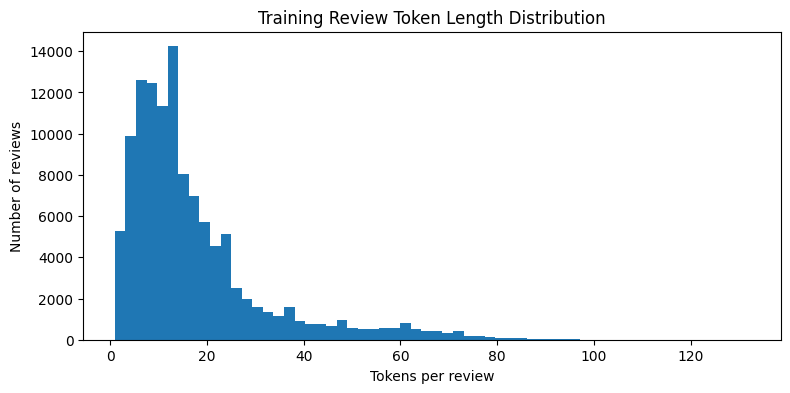

In [37]:
import numpy as np
import matplotlib.pyplot as plt

# 학습용 리뷰를 토큰 ID 목록으로 변환합니다.
# 나중에도 사용할 수 있도록 결과를 보관합니다.
train_sequences = [
    sp_nsmc.encode(review, out_type=int)
    for review in train_df["document"]
]

train_lengths = np.array([
    len(sequence) for sequence in train_sequences
])

print("최소 토큰 수:", train_lengths.min())
print("평균 토큰 수:", round(train_lengths.mean(), 2))
print("최대 토큰 수:", train_lengths.max())

for percentile in [50, 90, 95, 99]:
    value = np.percentile(train_lengths, percentile)
    print(f"{percentile}% 지점의 토큰 수: {value:.1f}")

print("토큰이 0개인 리뷰 수:", (train_lengths == 0).sum())

plt.figure(figsize=(9, 4))
plt.hist(train_lengths, bins=60)
plt.xlabel("Tokens per review")
plt.ylabel("Number of reviews")
plt.title("Training Review Token Length Distribution")
plt.show()


In [38]:
# 이미 학습한 토크나이저로 검증용 리뷰도 변환
val_sequences = [
    sp_nsmc.encode(review, out_type=int)
    for review in val_df["document"]
]

train_labels = train_df["label"].to_numpy()
val_labels = val_df["label"].to_numpy()

In [39]:
from torch.utils.data import Dataset

class ReviewDataset(Dataset):
    def __init__(self, sequences, labels):
        self.sequences = sequences
        self.labels = labels

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        review = torch.tensor(
            self.sequences[idx], dtype=torch.long
        )
        label = torch.tensor(
            self.labels[idx], dtype=torch.long
        )
        return review, label


train_dataset = ReviewDataset(train_sequences, train_labels)
val_dataset = ReviewDataset(val_sequences, val_labels)

review_ids, label = train_dataset[0]

print("첫 학습용 리뷰:", train_df.iloc[0]["document"])
print("토큰 ID:", review_ids)
print("정답 라벨:", label.item())
print("전체 학습용 개수:", len(train_dataset))

첫 학습용 리뷰: 뭔지 몰라도 추억의 영구형님영화ㅎㅎ
토큰 ID: tensor([1931, 2896, 2858,  709,  101, 3381,   29,  515])
정답 라벨: 1
전체 학습용 개수: 116820


# 동적 패딩


In [40]:
from torch.utils.data import DataLoader

def collate_batch(batch):
    # 리뷰·정답 쌍들을 각각 모읍니다.
    reviews, labels = zip(*batch)

    # PAD를 넣기 전의 실제 길이를 보관합니다.
    lengths = torch.tensor(
        [len(review) for review in reviews],
        dtype=torch.long
    )

    # 이번 배치의 최장 리뷰에 맞춰 PAD를 채웁니다.
    padded_reviews = pad_sequence(
        reviews,
        batch_first=True,
        padding_value=sp_nsmc.pad_id()
    )

    labels = torch.stack(labels)

    return padded_reviews, lengths, labels


BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch,
    generator=torch.Generator().manual_seed(SEED)
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch
)

# 검증용 첫 배치로 구조를 확인합니다.
batch_reviews, batch_lengths, batch_labels = next(iter(val_loader))

print("리뷰 배치 크기:", batch_reviews.shape)
print("이번 배치의 최장 길이:", batch_lengths.max().item())
print("첫 리뷰의 실제 길이:", batch_lengths[0].item())
print("첫 리뷰의 패딩 포함 ID:", batch_reviews[0])
print("정답 배치 크기:", batch_labels.shape)


리뷰 배치 크기: torch.Size([64, 57])
이번 배치의 최장 길이: 57
첫 리뷰의 실제 길이: 19
첫 리뷰의 패딩 포함 ID: tensor([  62,  270, 7441,  544,    2, 2533,   97, 1333,  809,   97,   56, 1375,
          16, 1104,  393,   13,  399, 3311, 2050,    1,    1,    1,    1,    1,
           1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
           1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
           1,    1,    1,    1,    1,    1,    1,    1,    1])
정답 배치 크기: torch.Size([64])


토큰 ID
   ↓ Embedding: ID마다 학습 가능한 벡터를 꺼냄
벡터의 나열
   ↓ LSTM: 앞에서부터 읽으며 정보를 갱신
리뷰를 요약한 벡터
   ↓ Linear: 긍정·부정 점수 계산
[부정 점수, 긍정 점수]

In [41]:
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence

torch.manual_seed(SEED)

class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, pad_id):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=128,
            padding_idx=pad_id
        )

        self.lstm = nn.LSTM(
            input_size=128,
            hidden_size=128,
            batch_first=True
        )

        self.classifier = nn.Linear(128, 2)

    def forward(self, reviews, lengths):
        embedded = self.embedding(reviews)

        # 실제 리뷰 길이를 알려 주어 LSTM이 뒤의 PAD를 읽지 않게 합니다.
        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, (hidden, _) = self.lstm(packed)

        # 마지막 LSTM 층의 최종 은닉 상태로 분류합니다.
        logits = self.classifier(hidden[-1])
        return logits


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = SentimentLSTM(
    vocab_size=sp_nsmc.get_piece_size(),
    pad_id=sp_nsmc.pad_id()
).to(device)

model.eval()
with torch.no_grad():
    sample_logits = model(
        batch_reviews.to(device),
        batch_lengths
    )

print("사용 장치:", device)
print("출력 크기:", sample_logits.shape)
print("첫 리뷰의 [부정 점수, 긍정 점수]:",
      sample_logits[0].cpu())

사용 장치: cuda
출력 크기: torch.Size([64, 2])
첫 리뷰의 [부정 점수, 긍정 점수]: tensor([0.0304, 0.0027])


In [42]:
probabilities = torch.softmax(sample_logits, dim=1)

print("첫 리뷰의 [부정 확률, 긍정 확률]:",
      probabilities[0].cpu())
print("확률의 합:", probabilities[0].sum().item())

첫 리뷰의 [부정 확률, 긍정 확률]: tensor([0.5069, 0.4931])
확률의 합: 0.9999999403953552


In [43]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

def train_one_epoch(model, loader):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_count = 0

    for reviews, lengths, labels in loader:
        reviews = reviews.to(device)
        labels = labels.to(device)

        # 이전 배치에서 계산한 기울기를 비웁니다.
        optimizer.zero_grad()

        logits = model(reviews, lengths)
        loss = criterion(logits, labels)

        # 현재 배치의 오차로 기울기를 계산하고 모델을 수정합니다.
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (
            logits.argmax(dim=1) == labels
        ).sum().item()
        total_count += batch_size

    return (
        total_loss / total_count,
        total_correct / total_count
    )


In [44]:
def evaluate(model, loader):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_count = 0

    with torch.no_grad():
        for reviews, lengths, labels in loader:
            reviews = reviews.to(device)
            labels = labels.to(device)

            logits = model(reviews, lengths)
            loss = criterion(logits, labels)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()
            total_count += batch_size

    return (
        total_loss / total_count,
        total_correct / total_count
    )

# 학습이 진행되면 train loss는 전반적으로 감소하고, validation loss도 초기에는 함께 감소할 것으로 예상한다. 이후 과적합으로 validation loss가 증가할 수 있으며, 학습을 더 진행하면 다시 감소하는 epoch-wise double descent가 나타날 가능성도 생각해 본다. 다만 단순한 변동과 구별해야 하므로 실제 학습 곡선을 보고 판단하겠다.

In [45]:
import time

MAX_EPOCHS = 10
best_val_loss = float("inf")
best_epoch = None
history = []

checkpoint_path = f"{model_prefix}_lstm_best.pt"

for epoch in range(1, MAX_EPOCHS + 1):
    start = time.perf_counter()

    train_loss, train_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc = evaluate(model, val_loader)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_acc": train_acc,
        "val_acc": val_acc
    })

    saved = ""
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "val_loss": val_loss,
            "val_acc": val_acc
        }, checkpoint_path)

        saved = " ← 최적 모델 저장"

    # 중간에 멈추더라도 완료된 epoch 기록은 파일로 남깁니다.
    pd.DataFrame(history).to_csv(
        f"{model_prefix}_lstm_history.csv", index=False
    )

    elapsed = time.perf_counter() - start

    print(
        f"Epoch {epoch:02d} | "
        f"train loss {train_loss:.4f}, acc {train_acc:.2%} | "
        f"val loss {val_loss:.4f}, acc {val_acc:.2%} | "
        f"{elapsed:.1f}초{saved}",
        flush=True
    )

print(f"\n검증 loss 기준 최적 epoch: {best_epoch}")

Epoch 01 | train loss 0.4494, acc 78.51% | val loss 0.3725, acc 83.61% | 19.3초 ← 최적 모델 저장
Epoch 02 | train loss 0.3187, acc 86.28% | val loss 0.3401, acc 85.11% | 23.3초 ← 최적 모델 저장
Epoch 03 | train loss 0.2646, acc 88.87% | val loss 0.3413, acc 85.15% | 18.7초
Epoch 04 | train loss 0.2120, acc 91.33% | val loss 0.3622, acc 85.14% | 19.8초
Epoch 05 | train loss 0.1528, acc 94.11% | val loss 0.4227, acc 84.59% | 19.7초
Epoch 06 | train loss 0.0977, acc 96.47% | val loss 0.5166, acc 84.44% | 19.5초
Epoch 07 | train loss 0.0603, acc 97.96% | val loss 0.6358, acc 84.25% | 20.3초
Epoch 08 | train loss 0.0373, acc 98.81% | val loss 0.7946, acc 84.25% | 19.0초
Epoch 09 | train loss 0.0281, acc 99.10% | val loss 0.8906, acc 84.21% | 19.7초
Epoch 10 | train loss 0.0248, acc 99.22% | val loss 0.9644, acc 84.03% | 21.7초

검증 loss 기준 최적 epoch: 2


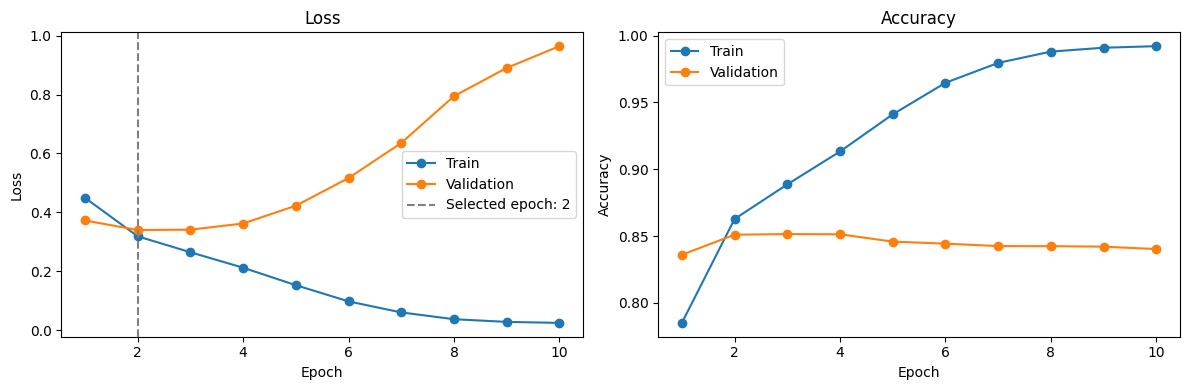

검증 loss 기준 선택 epoch: 2


In [46]:
history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    history_df["epoch"], history_df["train_loss"],
    marker="o", label="Train"
)
axes[0].plot(
    history_df["epoch"], history_df["val_loss"],
    marker="o", label="Validation"
)
axes[0].axvline(
    best_epoch, color="gray", linestyle="--",
    label=f"Selected epoch: {best_epoch}"
)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Loss")
axes[0].legend()

axes[1].plot(
    history_df["epoch"], history_df["train_acc"],
    marker="o", label="Train"
)
axes[1].plot(
    history_df["epoch"], history_df["val_acc"],
    marker="o", label="Validation"
)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Accuracy")
axes[1].legend()

plt.tight_layout()

Path("results").mkdir(exist_ok=True)
plt.savefig(
    "results/nsmc_unigram_8000_lstm_learning_curves.png",
    dpi=150, bbox_inches="tight"
)
plt.show()

print("검증 loss 기준 선택 epoch:", best_epoch)


# Train loss는 지속적으로 감소했지만, validation loss는 2 epoch에서 최저점에 도달한 뒤 계속 증가했다. 학습 정확도와 검증 정확도의 차이도 벌어져 과적합 양상이 나타났다. 예상했던 double descent는 이번 10 epoch 범위에서는 관찰되지 않았다. 따라서 사전에 정한 검증 loss 기준에 따라 마지막 epoch가 아닌 2 epoch의 모델을 선택했다


# 2에포크 시점 파라미터 불러오기 체크포인트.



In [47]:
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])

restored_loss, restored_acc = evaluate(model, val_loader)

print("불러온 모델의 epoch:", checkpoint["epoch"])
print(f"복원 후 검증 loss: {restored_loss:.4f}")
print(f"복원 후 검증 정확도: {restored_acc:.2%}")

불러온 모델의 epoch: 2
복원 후 검증 loss: 0.3401
복원 후 검증 정확도: 85.11%


In [48]:
test_url = (
    "https://raw.githubusercontent.com/"
    "e9t/nsmc/master/ratings_test.txt"
)

test_raw = pd.read_csv(test_url, sep="\t")

print("테스트 데이터의 원래 크기:", test_raw.shape)
print("\n열별 결측값 수:")
print(test_raw.isna().sum())

display(test_raw.head())

테스트 데이터의 원래 크기: (50000, 3)

열별 결측값 수:
id          0
document    3
label       0
dtype: int64


,id,document,label
0,6270596,굳 ㅋ,1
1,9274899,GDNTOPCLASSINTHECLUB,0
2,8544678,뭐야 이 평점들은.... 나쁘진 않지만 10점 짜리는 더더욱 아니잖아,0
3,6825595,지루하지는 않은데 완전 막장임... 돈주고 보기에는....,0
4,6723715,3D만 아니었어도 별 다섯 개 줬을텐데.. 왜 3D로 나와서 제 심기를 불편하게 하죠??,0


In [49]:
# 본문이 없는 행과 공백뿐인 행 제외
test_clean = test_raw.dropna(subset=["document"]).copy()
test_clean = test_clean[
    test_clean["document"].str.strip().ne("")
].reset_index(drop=True)

# 학습할 때 만든 토크나이저를 그대로 사용
test_sequences = [
    sp_nsmc.encode(review, out_type=int)
    for review in test_clean["document"]
]

test_lengths = [len(sequence) for sequence in test_sequences]

print("평가할 테스트 리뷰 수:", len(test_clean))
print("토큰이 0개인 리뷰 수:", test_lengths.count(0))

# 학습·검증 데이터에서 이미 등장했던 본문이 있는지 확인
seen_reviews = set(train_clean["document"])
overlap_mask = test_clean["document"].isin(seen_reviews)

print("학습·검증 데이터와 본문이 겹치는 테스트 행 수:",
      overlap_mask.sum())

평가할 테스트 리뷰 수: 49997
토큰이 0개인 리뷰 수: 0
학습·검증 데이터와 본문이 겹치는 테스트 행 수: 1147


In [50]:
test_dataset = ReviewDataset(
    test_sequences,
    test_clean["label"].to_numpy()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch
)

test_loss, test_acc = evaluate(model, test_loader)

print("평가한 모델의 epoch:", checkpoint["epoch"])
print("테스트 리뷰 수:", len(test_dataset))
print(f"테스트 loss: {test_loss:.4f}")
print(f"테스트 정확도: {test_acc:.2%}")

평가한 모델의 epoch: 2
테스트 리뷰 수: 49997
테스트 loss: 0.3487
테스트 정확도: 84.88%


In [51]:
from torch.utils.data import Subset

# 학습·검증 데이터에 등장하지 않은 본문의 인덱스
unseen_indices = np.flatnonzero(
    ~overlap_mask.to_numpy()
).tolist()

unseen_test_dataset = Subset(test_dataset, unseen_indices)

unseen_test_loader = DataLoader(
    unseen_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch
)

unseen_loss, unseen_acc = evaluate(model, unseen_test_loader)

print("본문이 겹치지 않는 테스트 리뷰 수:",
      len(unseen_test_dataset))
print(f"테스트 loss: {unseen_loss:.4f}")
print(f"테스트 정확도: {unseen_acc:.2%}")


본문이 겹치지 않는 테스트 리뷰 수: 48850
테스트 loss: 0.3516
테스트 정확도: 84.68%


# 전체 유효 테스트 리뷰 49,997개에서 정확도 84.88%를 얻었다. 학습·검증 데이터와 본문이 정확히 일치하는 리뷰를 제외한 48,850개에서는 84.68%였다. 중복 본문을 제외한 경우에도 80% 이상의 정확도를 유지했다.


In [52]:
baseline_result = {
    "tokenizer": "unigram",
    "vocab_size": sp_nsmc.get_piece_size(),
    "classifier": "LSTM",
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "selected_epoch": checkpoint["epoch"],
    "val_loss": restored_loss,
    "val_accuracy": restored_acc,
    "test_count": len(test_dataset),
    "test_loss": test_loss,
    "test_accuracy": test_acc,
    "nonoverlap_test_count": len(unseen_test_dataset),
    "nonoverlap_test_loss": unseen_loss,
    "nonoverlap_test_accuracy": unseen_acc
}

comparison_results = [baseline_result]

pd.DataFrame(comparison_results).to_csv(
    "results/tokenizer_comparison.csv",
    index=False
)

print("첫 실험 결과를 저장했습니다.")

첫 실험 결과를 저장했습니다.


# BPE 로 전환시 사전이 달라지니 , 초기화된 모델 사용


In [53]:
bpe_model_prefix = "nsmc_bpe_8000"

spm.SentencePieceTrainer.train(
    input=str(corpus_path),
    model_prefix=bpe_model_prefix,
    model_type="bpe",  # 이전 실험과 달라지는 설정
    vocab_size=8000,
    character_coverage=0.9995,
    unk_id=0,
    pad_id=1,
    bos_id=-1,
    eos_id=-1
)

sp_bpe = spm.SentencePieceProcessor(
    model_file=f"{bpe_model_prefix}.model"
)

print("BPE 사전 크기:", sp_bpe.get_piece_size())
print("UNK ID:", sp_bpe.unk_id())
print("PAD ID:", sp_bpe.pad_id())

review = "이 영화 진짜 재밌어요ㅋㅋ"

print("\nunigram 토큰:", sp_nsmc.encode(review, out_type=str))
print("BPE 토큰:    ", sp_bpe.encode(review, out_type=str))

print("\nunigram ID:", sp_nsmc.encode(review, out_type=int))
print("BPE ID:    ", sp_bpe.encode(review, out_type=int))

BPE 사전 크기: 8000
UNK ID: 0
PAD ID: 1

unigram 토큰: ['▁이', '▁영화', '▁진짜', '▁재밌어요', 'ᄏᄏ']
BPE 토큰:     ['▁이', '▁영화', '▁진짜', '▁재밌어요', 'ᄏᄏ']

unigram ID: [27, 6, 31, 743, 137]
BPE ID:     [5, 4, 53, 917, 8]


실제 같은 토큰이 다른 id로 매핑된 모습

In [54]:
bpe_train_sequences = [
    sp_bpe.encode(review, out_type=int)
    for review in train_df["document"]
]

bpe_val_sequences = [
    sp_bpe.encode(review, out_type=int)
    for review in val_df["document"]
]

bpe_train_dataset = ReviewDataset(
    bpe_train_sequences, train_labels
)

bpe_val_dataset = ReviewDataset(
    bpe_val_sequences, val_labels
)

bpe_train_lengths = np.array([
    len(sequence) for sequence in bpe_train_sequences
])

print("BPE 학습용 리뷰 수:", len(bpe_train_dataset))
print("BPE 검증용 리뷰 수:", len(bpe_val_dataset))
print("BPE에서 토큰이 0개인 학습용 리뷰 수:",
      (bpe_train_lengths == 0).sum())

display(pd.DataFrame({
    "unigram": [
        train_lengths.mean(),
        np.percentile(train_lengths, 95),
        train_lengths.max()
    ],
    "BPE": [
        bpe_train_lengths.mean(),
        np.percentile(bpe_train_lengths, 95),
        bpe_train_lengths.max()
    ]
}, index=["평균 토큰 수", "95% 지점", "최대 토큰 수"]))

BPE 학습용 리뷰 수: 116820
BPE 검증용 리뷰 수: 29205
BPE에서 토큰이 0개인 학습용 리뷰 수: 0


,unigram,BPE
평균 토큰 수,17.35743,17.021289
95% 지점,52.00000,51.000000
최대 토큰 수,132.00000,130.000000


두 토큰화 기법이 비슷하게 , 토큰화를 한모습이다


In [55]:
# 기존 배치 함수는 unigram의 PAD ID를 참조합니다.
# 두 토크나이저 모두 PAD가 1이므로 그대로 사용할 수 있습니다.
assert sp_bpe.pad_id() == sp_nsmc.pad_id() == 1

bpe_train_loader = DataLoader(
    bpe_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch,
    generator=torch.Generator().manual_seed(SEED)
)

bpe_val_loader = DataLoader(
    bpe_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch
)

# 기존 모델을 이어 쓰지 않고 같은 시드로 새 모델을 만듭니다.
torch.manual_seed(SEED)

bpe_model = SentimentLSTM(
    vocab_size=sp_bpe.get_piece_size(),
    pad_id=sp_bpe.pad_id()
).to(device)

# 학습 함수가 참조하는 optimizer도 새 모델에 맞춰 교체합니다.
optimizer = torch.optim.Adam(
    bpe_model.parameters(),
    lr=0.001
)

print("BPE 모델 준비 완료")
print("사용 장치:", device)
print("학습용 배치 수:", len(bpe_train_loader))
print("검증용 배치 수:", len(bpe_val_loader))

BPE 모델 준비 완료
사용 장치: cuda
학습용 배치 수: 1826
검증용 배치 수: 457


Unigram이 BPE보다 감성 분류에서 더 높은 성능을 보일 것으로 예상한다. 가능한 분할의 확률을 고려하는 방식이 감정 표현을 유용한 토큰 단위로 나누는 데 도움이 될 수 있다고 생각하기 때문이다. 다만 분할 확률이 높은 것이 감성 분류에 유리하다는 뜻은 아니므로, 실제 검증 결과로 이 예상을 확인하겠다.

| 구분 | BPE | unigram |
|---|---|---|
| 사전 만들기 | 작은 조각들을 합침 | 많은 후보에서 불필요한 조각을 덜어 냄 |
| 핵심 기준 | 인접한 토큰 쌍의 빈도 | 확률 모델로 말뭉치를 얼마나 잘 설명하는가 |
| 기본 토큰화 | 배운 병합 순서 적용 | 가장 확률 높은 분할 선택 |

In [56]:
bpe_best_val_loss = float("inf")
bpe_best_epoch = None
bpe_history = []

bpe_checkpoint_path = f"{bpe_model_prefix}_lstm_best.pt"

for epoch in range(1, MAX_EPOCHS + 1):
    start = time.perf_counter()

    train_loss, train_acc = train_one_epoch(
        bpe_model, bpe_train_loader
    )
    val_loss, val_acc = evaluate(
        bpe_model, bpe_val_loader
    )

    bpe_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_acc": train_acc,
        "val_acc": val_acc
    })

    saved = ""
    if val_loss < bpe_best_val_loss:
        bpe_best_val_loss = val_loss
        bpe_best_epoch = epoch

        torch.save({
            "epoch": epoch,
            "model_state_dict": bpe_model.state_dict(),
            "val_loss": val_loss,
            "val_acc": val_acc
        }, bpe_checkpoint_path)

        saved = " | 검증 loss 최저 갱신 → 모델 저장"

    pd.DataFrame(bpe_history).to_csv(
        f"{bpe_model_prefix}_lstm_history.csv",
        index=False
    )

    elapsed = time.perf_counter() - start

    print(
        f"Epoch {epoch:02d} | "
        f"train loss {train_loss:.4f}, acc {train_acc:.2%} | "
        f"val loss {val_loss:.4f}, acc {val_acc:.2%} | "
        f"{elapsed:.1f}초{saved}",
        flush=True
    )

print(f"\nBPE 검증 loss 기준 선택 epoch: {bpe_best_epoch}")

Epoch 01 | train loss 0.4503, acc 78.55% | val loss 0.3691, acc 83.58% | 20.9초 | 검증 loss 최저 갱신 → 모델 저장
Epoch 02 | train loss 0.3200, acc 86.18% | val loss 0.3402, acc 85.13% | 19.2초 | 검증 loss 최저 갱신 → 모델 저장
Epoch 03 | train loss 0.2661, acc 88.81% | val loss 0.3405, acc 85.42% | 20.4초
Epoch 04 | train loss 0.2115, acc 91.52% | val loss 0.3649, acc 85.14% | 18.5초
Epoch 05 | train loss 0.1521, acc 94.13% | val loss 0.4336, acc 84.66% | 22.8초
Epoch 06 | train loss 0.0977, acc 96.49% | val loss 0.5308, acc 84.44% | 22.3초
Epoch 07 | train loss 0.0578, acc 98.07% | val loss 0.6718, acc 84.12% | 20.9초
Epoch 08 | train loss 0.0370, acc 98.83% | val loss 0.7949, acc 84.32% | 19.6초
Epoch 09 | train loss 0.0272, acc 99.16% | val loss 0.8902, acc 84.05% | 18.9초
Epoch 10 | train loss 0.0231, acc 99.26% | val loss 0.9627, acc 83.81% | 18.7초

BPE 검증 loss 기준 선택 epoch: 2


In [57]:
# 검증 loss가 가장 낮았던 BPE 모델 복원
bpe_checkpoint = torch.load(
    bpe_checkpoint_path,
    map_location=device,
    weights_only=True
)
bpe_model.load_state_dict(bpe_checkpoint["model_state_dict"])

# unigram 평가와 정확히 같은 리뷰·라벨 사용
bpe_test_sequences = [
    sp_bpe.encode(review, out_type=int)
    for review in test_clean["document"]
]

assert all(len(sequence) > 0 for sequence in bpe_test_sequences)

bpe_test_dataset = ReviewDataset(
    bpe_test_sequences,
    test_clean["label"].to_numpy()
)

bpe_test_loader = DataLoader(
    bpe_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch
)

# 본문이 겹치지 않는 평가도 기존과 같은 인덱스 사용
bpe_unseen_loader = DataLoader(
    Subset(bpe_test_dataset, unseen_indices),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch
)

bpe_test_loss, bpe_test_acc = evaluate(
    bpe_model, bpe_test_loader
)
bpe_unseen_loss, bpe_unseen_acc = evaluate(
    bpe_model, bpe_unseen_loader
)

print("BPE 평가 모델 epoch:", bpe_checkpoint["epoch"])
print(f"전체 유효 테스트 정확도: {bpe_test_acc:.2%}")
print(f"본문 비중복 테스트 정확도: {bpe_unseen_acc:.2%}")

BPE 평가 모델 epoch: 2
전체 유효 테스트 정확도: 84.67%
본문 비중복 테스트 정확도: 84.48%


# Unigram이 감성 분류에 더 유리할 것으로 예상했다. 실험에서는 unigram의 전체 테스트 정확도가 84.88%로 BPE의 84.67%보다 0.21%p 높았다. 반면 검증 정확도는 두 방식이 거의 같았으며 BPE가 근소하게 높았다. 따라서 이번 실행의 테스트 결과는 예측한 방향과 일치했지만, unigram의 일반적인 우위를 주장하기에는 근거가 부족하다. 또한 BPE의 평균 토큰 수가 더 적었으므로, 짧은 토큰열이 반드시 높은 분류 정확도로 이어지는 것은 아니었다.

In [58]:
bpe_result = {
    "tokenizer": "bpe",
    "vocab_size": sp_bpe.get_piece_size(),
    "classifier": "LSTM",
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "selected_epoch": bpe_checkpoint["epoch"],
    "val_loss": bpe_checkpoint["val_loss"],
    "val_accuracy": bpe_checkpoint["val_acc"],
    "test_count": len(bpe_test_dataset),
    "test_loss": bpe_test_loss,
    "test_accuracy": bpe_test_acc,
    "nonoverlap_test_count": len(unseen_indices),
    "nonoverlap_test_loss": bpe_unseen_loss,
    "nonoverlap_test_accuracy": bpe_unseen_acc
}

# 이 셀을 재실행해도 BPE 결과가 중복으로 추가되지 않게 처리
comparison_results = [
    result for result in comparison_results
    if result["tokenizer"] != "bpe"
]
comparison_results.append(bpe_result)

comparison_df = pd.DataFrame(comparison_results)
comparison_df.to_csv(
    "results/tokenizer_comparison.csv",
    index=False
)

display(comparison_df[[
    "tokenizer",
    "vocab_size",
    "selected_epoch",
    "val_accuracy",
    "test_accuracy",
    "nonoverlap_test_accuracy"
]])


,tokenizer,vocab_size,selected_epoch,val_accuracy,test_accuracy,nonoverlap_test_accuracy
0,unigram,8000,2,0.851053,0.848811,0.846837
1,bpe,8000,2,0.851327,0.846671,0.844770


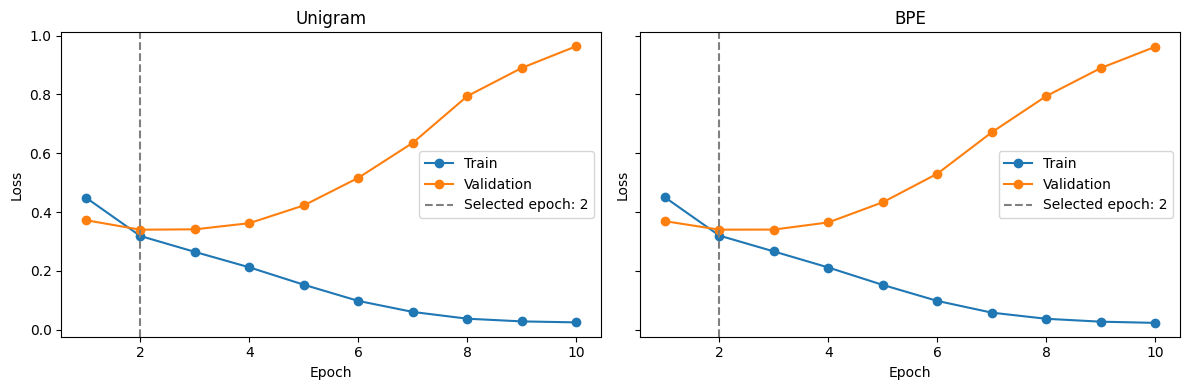

In [59]:
Path("results").mkdir(exist_ok=True)

unigram_history_df = pd.DataFrame(history)
bpe_history_df = pd.DataFrame(bpe_history)

fig, axes = plt.subplots(
    1, 2, figsize=(12, 4), sharex=True, sharey=True
)

experiments = [
    ("Unigram", unigram_history_df, baseline_result["selected_epoch"]),
    ("BPE", bpe_history_df, bpe_result["selected_epoch"])
]

for ax, (name, records, selected_epoch) in zip(axes, experiments):
    ax.plot(
        records["epoch"], records["train_loss"],
        marker="o", label="Train"
    )
    ax.plot(
        records["epoch"], records["val_loss"],
        marker="o", label="Validation"
    )
    ax.axvline(
        selected_epoch,
        color="gray", linestyle="--",
        label=f"Selected epoch: {selected_epoch}"
    )
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()

plt.tight_layout()
plt.savefig(
    "results/tokenizer_loss_comparison.png",
    dpi=150, bbox_inches="tight"
)
plt.show()

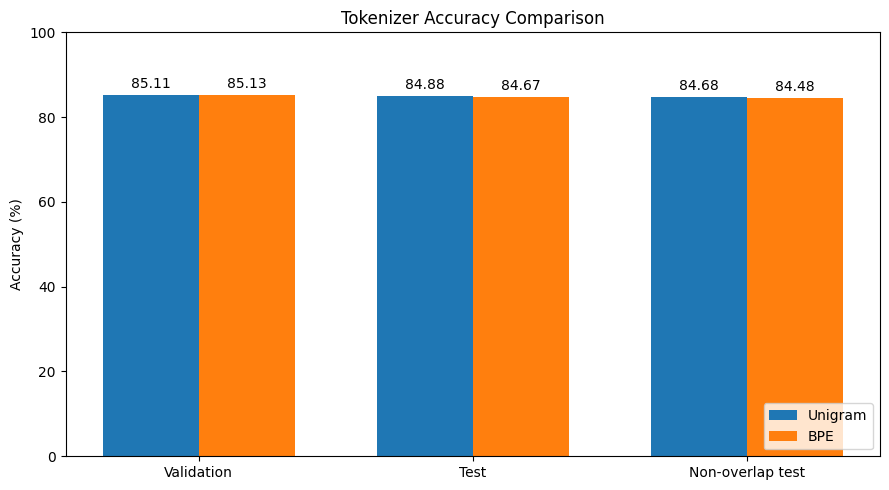

In [60]:
metric_keys = [
    "val_accuracy",
    "test_accuracy",
    "nonoverlap_test_accuracy"
]
metric_labels = [
    "Validation",
    "Test",
    "Non-overlap test"
]

unigram_scores = [
    baseline_result[key] * 100 for key in metric_keys
]
bpe_scores = [
    bpe_result[key] * 100 for key in metric_keys
]

x = np.arange(len(metric_labels))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars_unigram = ax.bar(
    x - width / 2, unigram_scores, width, label="Unigram"
)
bars_bpe = ax.bar(
    x + width / 2, bpe_scores, width, label="BPE"
)

ax.bar_label(bars_unigram, fmt="%.2f", padding=3)
ax.bar_label(bars_bpe, fmt="%.2f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(metric_labels)
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)
ax.set_title("Tokenizer Accuracy Comparison")
ax.legend(loc="lower right")

plt.tight_layout()
plt.savefig(
    "results/tokenizer_accuracy_comparison.png",
    dpi=150, bbox_inches="tight"
)
plt.show()

# Loss 비교: 두 방식 모두 2 epoch에서 검증 loss가 가장 낮았으며, 이후 train loss는 감소하고 validation loss는 증가했다. 토큰화 방식을 바꾸어도 이번 설정에서는 유사한 과적합 양상이 나타났다.

# 정확도 비교: 검증 정확도는 거의 같았고, 전체 테스트와 본문 비중복 테스트에서는 unigram이 약 0.2%p 높았다. 이번 단일 시드 실험에서는 토큰화 방식에 따른 큰 성능 차이가 관찰되지 않았다.

# 어떤 리뷰를 틀렸는지, 그리고 두 모델의 판단이 어디서 갈리는지


In [61]:
def collect_predictions(model, loader):
    model.eval()

    predictions = []
    positive_probs = []

    with torch.no_grad():
        for reviews, lengths, labels in loader:
            logits = model(reviews.to(device), lengths)
            probs = torch.softmax(logits, dim=1)

            predictions.extend(
                logits.argmax(dim=1).cpu().tolist()
            )
            positive_probs.extend(
                probs[:, 1].cpu().tolist()
            )

    return predictions, positive_probs


unigram_preds, unigram_probs = collect_predictions(
    model, test_loader
)
bpe_preds, bpe_probs = collect_predictions(
    bpe_model, bpe_test_loader
)

In [62]:
error_analysis = test_clean[["document", "label"]].copy()

error_analysis["unigram_pred"] = unigram_preds
error_analysis["unigram_positive_prob"] = unigram_probs

error_analysis["bpe_pred"] = bpe_preds
error_analysis["bpe_positive_prob"] = bpe_probs

unigram_wrong = (
    error_analysis["unigram_pred"] != error_analysis["label"]
)
bpe_wrong = (
    error_analysis["bpe_pred"] != error_analysis["label"]
)
disagreement = (
    error_analysis["unigram_pred"] != error_analysis["bpe_pred"]
)

print("Unigram 오분류 수:", unigram_wrong.sum())
print("BPE 오분류 수:", bpe_wrong.sum())
print("두 모델 모두 오분류한 수:", (unigram_wrong & bpe_wrong).sum())
print("두 모델의 판단이 다른 리뷰 수:", disagreement.sum())

print("\nUnigram 오분류 예시 5개:")
display(error_analysis.loc[unigram_wrong].head(5))

print("\n두 모델의 판단이 다른 예시 5개:")
display(error_analysis.loc[disagreement].head(5))

error_analysis.to_csv(
    "results/test_review_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

Unigram 오분류 수: 7559
BPE 오분류 수: 7666
두 모델 모두 오분류한 수: 5244
두 모델의 판단이 다른 리뷰 수: 4737

Unigram 오분류 예시 5개:


,document,label,unigram_pred,unigram_positive_prob,bpe_pred,bpe_positive_prob
1,GDNTOPCLASSINTHECLUB,0,1,0.869604,1,0.817292
11,한국독립영화의 한계 그렇게 아버지가 된다와 비교됨,0,1,0.630359,1,0.601762
13,눈에 보이는 반전이었지만 영화의 흡인력은 사라지지 않았다.,1,0,0.331344,0,0.301225
15,소위 ㅈ문가라는 평점은 뭐냐?,1,0,0.062554,0,0.129266
23,민주화 시대의 억눌린 영혼의 관음적인 욕구 분출.인상적이다.,1,0,0.091296,0,0.387263



두 모델의 판단이 다른 예시 5개:


,document,label,unigram_pred,unigram_positive_prob,bpe_pred,bpe_positive_prob
39,셰익스피어는 셰익스피어고 이영화는 이영화.,0,1,0.654925,0,0.494702
43,애니는 일본이 갑인듯.,1,1,0.714346,0,0.499818
51,레이토와 다미앙의 시원한 액션은 어디갔나 ㅁㅊ,0,1,0.758957,0,0.360054
53,아 극장에서 아무 기대없이 들어갔다가 감탄하면서 보고 나왔는데. 2001년도 였구나...,1,1,0.880776,0,0.383587
57,몇년만에 아메리칸조크보고 웃어보는거지. 하아이맛이야바로,1,1,0.530133,0,0.350191


오분류 사례를 살펴보니, 상반된 평가와 부정 표현이 함께 등장하는 문장에서 두 모델 모두 판단에 실패한 경우가 있었다. 또한 영화 자체를 비판하는 것인지, 영화를 평가한 사람을 비판하는 것인지 구별해야 하는 사례도 보였다.

“애니는 일본이 갑인듯.”처럼 문맥에 따라 해석이 달라질 수 있는 리뷰도 있었다. 해당 영화를 칭찬하는 말인지, 일본 애니메이션과 비교해 낮게 평가하는 말인지 본문만으로는 확정하기 어렵게 느껴졌다. 따라서 오분류를 분석할 때는 모델의 한계뿐 아니라, 사람도 판단하기 어려운 문맥 부족과 라벨의 모호함을 함께 고려해야겠다고 생각했다

In [63]:
for idx in [43, 51, 53]:
    review = error_analysis.loc[idx, "document"]

    print("리뷰:", review)
    print("Unigram:", sp_nsmc.encode(review, out_type=str))
    print("BPE:    ", sp_bpe.encode(review, out_type=str))
    print()

리뷰: 애니는 일본이 갑인듯.
Unigram: ['▁애니', '는', '▁일본', '이', '▁갑', '인듯', '.']
BPE:     ['▁애니', '는', '▁일본', '이', '▁갑', '인듯', '.']

리뷰: 레이토와 다미앙의 시원한 액션은 어디갔나 ㅁㅊ
Unigram: ['▁', '레이', '토', '와', '▁다', '미', '앙', '의', '▁시원', '한', '▁액션은', '▁어디', '갔', '나', '▁', 'ᄆ', 'ᄎ']
BPE:     ['▁레이', '토', '와', '▁다', '미', '앙', '의', '▁시원', '한', '▁액션은', '▁어디', '갔', '나', '▁', 'ᄆ', 'ᄎ']

리뷰: 아 극장에서 아무 기대없이 들어갔다가 감탄하면서 보고 나왔는데. 2001년도 였구나 그 때가.
Unigram: ['▁아', '▁극장에서', '▁아무', '▁기대없이', '▁들어', '갔다', '가', '▁감탄', '하면서', '▁보고', '▁나왔', '는데', '.', '▁', '200', '1', '년도', '▁', '였구나', '▁그', '▁때', '가', '.']
BPE:     ['▁아', '▁극장에서', '▁아무', '▁기대없이', '▁들어', '갔', '다가', '▁감탄', '하면서', '▁보고', '▁나왔', '는데', '.', '▁200', '1', '년도', '▁', '였', '구나', '▁그', '▁때', '가', '.']



# 똑같이 나눠도 다른 판단을 내림.ID와 학습된 Embedding·LSTM 파라미터가 서로 다르기 때문

예측이 달랐던 리뷰의 토큰 분할을 비교했다. 일부에서는 ‘갔다가’, ‘였구나’ 등의 분할 방식이 달랐지만, ‘애니는 일본이 갑인듯.’은 토큰 조각이 완전히 같았다. 따라서 예측 차이를 해당 리뷰의 분할 차이만으로 설명할 수는 없다. 토큰 ID와 전체 학습 데이터의 토큰화가 달라지면서 학습된 모델 파라미터도 달라진다는 점을 함께 고려해야 한다

# 사전 크기를 줄이는 실험


In [65]:
unigram4k_prefix = "nsmc_unigram_4000"

spm.SentencePieceTrainer.train(
    input=str(corpus_path),
    model_prefix=unigram4k_prefix,
    model_type="unigram",
    vocab_size=4000,  # unigram 첫 실험에서 바꾸는 설정
    character_coverage=0.9995,
    unk_id=0,
    pad_id=1,
    bos_id=-1,
    eos_id=-1
)

sp_unigram4k = spm.SentencePieceProcessor(
    model_file=f"{unigram4k_prefix}.model"
)

print("사전 크기:", sp_unigram4k.get_piece_size())
print("UNK ID:", sp_unigram4k.unk_id())
print("PAD ID:", sp_unigram4k.pad_id())

unigram4k_train_sequences = [
    sp_unigram4k.encode(review, out_type=int)
    for review in train_df["document"]
]

unigram4k_val_sequences = [
    sp_unigram4k.encode(review, out_type=int)
    for review in val_df["document"]
]

unigram4k_train_lengths = np.array([
    len(sequence) for sequence in unigram4k_train_sequences
])

print("토큰이 0개인 학습용 리뷰 수:",
      (unigram4k_train_lengths == 0).sum())

display(pd.DataFrame({
    "unigram_8000": [
        train_lengths.mean(),
        np.percentile(train_lengths, 95),
        train_lengths.max()
    ],
    "unigram_4000": [
        unigram4k_train_lengths.mean(),
        np.percentile(unigram4k_train_lengths, 95),
        unigram4k_train_lengths.max()
    ]
}, index=["평균 토큰 수", "95% 지점", "최대 토큰 수"]))

review = "이 영화 진짜 재밌어요ㅋㅋ"

print("8,000개 사전:", sp_nsmc.encode(review, out_type=str))
print("4,000개 사전:", sp_unigram4k.encode(review, out_type=str))

사전 크기: 4000
UNK ID: 0
PAD ID: 1
토큰이 0개인 학습용 리뷰 수: 0


,unigram_8000,unigram_4000
평균 토큰 수,17.35743,20.249914
95% 지점,52.00000,61.000000
최대 토큰 수,132.00000,135.000000


8,000개 사전: ['▁이', '▁영화', '▁진짜', '▁재밌어요', 'ᄏᄏ']
4,000개 사전: ['▁이', '▁영화', '▁진짜', '▁재밌어요', 'ᄏᄏ']


사전 크기가 줄어드니 평균토큰수가 늘어난모습


In [66]:
unigram4k_train_dataset = ReviewDataset(
    unigram4k_train_sequences, train_labels
)
unigram4k_val_dataset = ReviewDataset(
    unigram4k_val_sequences, val_labels
)

assert sp_unigram4k.pad_id() == sp_nsmc.pad_id() == 1

unigram4k_train_loader = DataLoader(
    unigram4k_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch,
    generator=torch.Generator().manual_seed(SEED)
)

unigram4k_val_loader = DataLoader(
    unigram4k_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch
)

torch.manual_seed(SEED)

unigram4k_model = SentimentLSTM(
    vocab_size=sp_unigram4k.get_piece_size(),
    pad_id=sp_unigram4k.pad_id()
).to(device)

optimizer = torch.optim.Adam(
    unigram4k_model.parameters(), lr=0.001
)

print("사전 8,000개 모델의 파라미터 수:",
      sum(p.numel() for p in model.parameters()))
print("사전 4,000개 모델의 파라미터 수:",
      sum(p.numel() for p in unigram4k_model.parameters()))

사전 8,000개 모델의 파라미터 수: 1156354
사전 4,000개 모델의 파라미터 수: 644354


사전이 줄어드니 확실히 파라미터가 줄은모습이다

속도는 빨라지고 정확도는 줄을거같다

In [67]:
unigram4k_best_val_loss = float("inf")
unigram4k_best_epoch = None
unigram4k_history = []

unigram4k_checkpoint_path = f"{unigram4k_prefix}_lstm_best.pt"

for epoch in range(1, MAX_EPOCHS + 1):
    start = time.perf_counter()

    train_loss, train_acc = train_one_epoch(
        unigram4k_model, unigram4k_train_loader
    )
    val_loss, val_acc = evaluate(
        unigram4k_model, unigram4k_val_loader
    )

    unigram4k_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_acc": train_acc,
        "val_acc": val_acc
    })

    saved = ""
    if val_loss < unigram4k_best_val_loss:
        unigram4k_best_val_loss = val_loss
        unigram4k_best_epoch = epoch

        torch.save({
            "epoch": epoch,
            "model_state_dict": unigram4k_model.state_dict(),
            "val_loss": val_loss,
            "val_acc": val_acc
        }, unigram4k_checkpoint_path)

        saved = " | 검증 loss 최저 갱신 → 모델 저장"

    pd.DataFrame(unigram4k_history).to_csv(
        f"{unigram4k_prefix}_lstm_history.csv",
        index=False
    )

    elapsed = time.perf_counter() - start

    print(
        f"Epoch {epoch:02d} | "
        f"train loss {train_loss:.4f}, acc {train_acc:.2%} | "
        f"val loss {val_loss:.4f}, acc {val_acc:.2%} | "
        f"{elapsed:.1f}초{saved}",
        flush=True
    )

print(
    "\nUnigram 4,000 검증 loss 기준 선택 epoch:",
    unigram4k_best_epoch
)


Epoch 01 | train loss 0.4410, acc 79.18% | val loss 0.3650, acc 83.87% | 23.9초 | 검증 loss 최저 갱신 → 모델 저장
Epoch 02 | train loss 0.3296, acc 85.68% | val loss 0.3489, acc 84.70% | 22.1초 | 검증 loss 최저 갱신 → 모델 저장
Epoch 03 | train loss 0.2827, acc 88.04% | val loss 0.3459, acc 84.93% | 20.1초 | 검증 loss 최저 갱신 → 모델 저장
Epoch 04 | train loss 0.2356, acc 90.30% | val loss 0.3611, acc 85.01% | 23.3초
Epoch 05 | train loss 0.1860, acc 92.71% | val loss 0.3949, acc 84.95% | 21.7초
Epoch 06 | train loss 0.1347, acc 94.91% | val loss 0.4709, acc 84.10% | 28.0초
Epoch 07 | train loss 0.0939, acc 96.68% | val loss 0.5413, acc 84.11% | 21.2초
Epoch 08 | train loss 0.0643, acc 97.84% | val loss 0.6632, acc 83.95% | 25.1초
Epoch 09 | train loss 0.0462, acc 98.49% | val loss 0.7597, acc 83.91% | 22.1초
Epoch 10 | train loss 0.0370, acc 98.78% | val loss 0.8173, acc 83.63% | 23.2초

Unigram 4,000 검증 loss 기준 선택 epoch: 3


| 사전을 줄였을 때 | 이유 |
|---|---|
| 문장의 토큰 수 증가 | 작은 조각을 여러 개 이어 써야 할 수 있음 |
| 모델 파라미터 수 감소 | 보관해야 할 토큰별 Embedding 벡터가 줄어듦 |
| LSTM이 읽는 단계 수 증가 | 입력 문장이 더 많은 토큰으로 표현됨 |


# 처음에는 사전을 줄이면 파라미터가 감소하므로 학습도 빨라질 것으로 예상했다. 그러나 평균 토큰 수가 증가해 LSTM의 처리 단계도 늘어난다는 점을 알게 되었다. 따라서 파라미터 감소만으로 속도를 예측하기는 어려우며, 실제 epoch별 실행 시간으로 확인하겠다.

In [68]:
unigram4k_checkpoint = torch.load(
    unigram4k_checkpoint_path,
    map_location=device,
    weights_only=True
)

unigram4k_model.load_state_dict(
    unigram4k_checkpoint["model_state_dict"]
)

unigram4k_test_sequences = [
    sp_unigram4k.encode(review, out_type=int)
    for review in test_clean["document"]
]

assert all(
    len(sequence) > 0
    for sequence in unigram4k_test_sequences
)

unigram4k_test_dataset = ReviewDataset(
    unigram4k_test_sequences,
    test_clean["label"].to_numpy()
)

unigram4k_test_loader = DataLoader(
    unigram4k_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch
)

unigram4k_unseen_loader = DataLoader(
    Subset(unigram4k_test_dataset, unseen_indices),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch
)

unigram4k_test_loss, unigram4k_test_acc = evaluate(
    unigram4k_model, unigram4k_test_loader
)
unigram4k_unseen_loss, unigram4k_unseen_acc = evaluate(
    unigram4k_model, unigram4k_unseen_loader
)

print("평가한 모델 epoch:", unigram4k_checkpoint["epoch"])
print(f"전체 유효 테스트 정확도: {unigram4k_test_acc:.2%}")
print(f"본문 비중복 테스트 정확도: {unigram4k_unseen_acc:.2%}")

평가한 모델 epoch: 3
전체 유효 테스트 정확도: 84.70%
본문 비중복 테스트 정확도: 84.49%


# Unigram의 사전 크기를 8,000개에서 4,000개로 줄이자 평균 토큰 수가 17.36개에서 20.25개로 증가했다. Embedding 파라미터는 512,000개 감소했지만, 테스트 정확도는 84.88%에서 84.70%로 소폭 하락했다. 따라서 이번 실험에서는 모델 크기를 줄이면서 비슷한 정확도를 유지할 수 있었다. 다만 입력 토큰열이 길어졌고 실행 시간도 빨라지지 않았으므로, 파라미터 감소가 곧 학습 속도 향상을 의미하지는 않았다. 이 결과는 단일 시드 실행에 대한 관찰이다.



In [69]:
unigram4k_result = {
    "tokenizer": "unigram",
    "vocab_size": sp_unigram4k.get_piece_size(),
    "classifier": "LSTM",
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "selected_epoch": unigram4k_checkpoint["epoch"],
    "val_loss": unigram4k_checkpoint["val_loss"],
    "val_accuracy": unigram4k_checkpoint["val_acc"],
    "test_count": len(unigram4k_test_dataset),
    "test_loss": unigram4k_test_loss,
    "test_accuracy": unigram4k_test_acc,
    "nonoverlap_test_count": len(unseen_indices),
    "nonoverlap_test_loss": unigram4k_unseen_loss,
    "nonoverlap_test_accuracy": unigram4k_unseen_acc
}

# 같은 설정이 이미 있으면 교체하여 중복 저장 방지
comparison_results = [
    result for result in comparison_results
    if not (
        result["tokenizer"] == "unigram"
        and result["vocab_size"] == 4000
    )
]
comparison_results.append(unigram4k_result)

comparison_df = pd.DataFrame(comparison_results)
comparison_df.to_csv(
    "results/tokenizer_comparison.csv",
    index=False
)

display(comparison_df[[
    "tokenizer",
    "vocab_size",
    "selected_epoch",
    "val_accuracy",
    "test_accuracy",
    "nonoverlap_test_accuracy"
]])

,tokenizer,vocab_size,selected_epoch,val_accuracy,test_accuracy,nonoverlap_test_accuracy
0,unigram,8000,2,0.851053,0.848811,0.846837
1,bpe,8000,2,0.851327,0.846671,0.844770
2,unigram,4000,3,0.849341,0.846971,0.844913


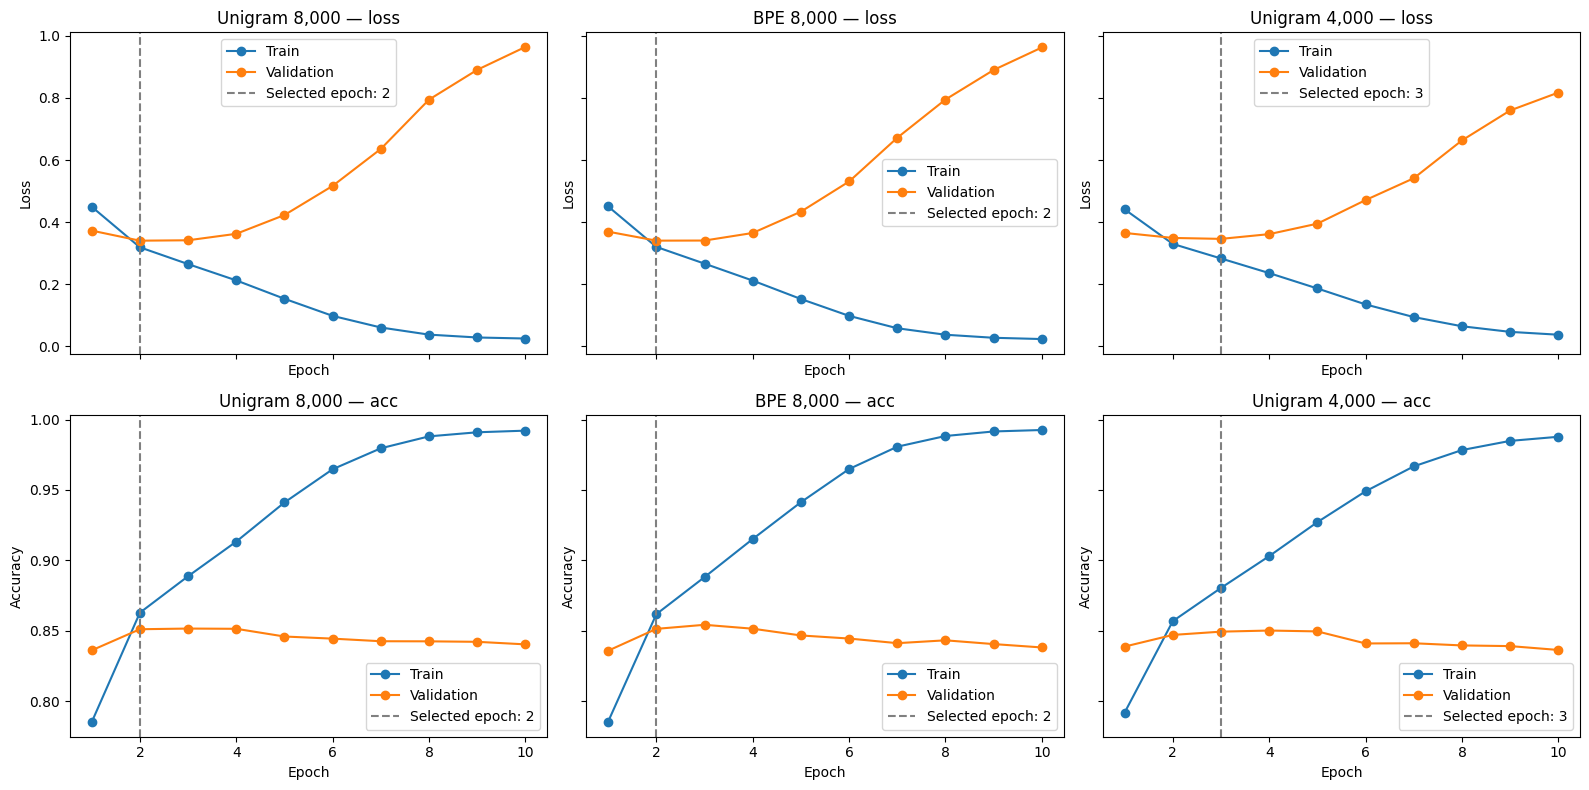

In [70]:
experiments = [
    (
        "Unigram 8,000",
        pd.DataFrame(history),
        baseline_result["selected_epoch"]
    ),
    (
        "BPE 8,000",
        pd.DataFrame(bpe_history),
        bpe_result["selected_epoch"]
    ),
    (
        "Unigram 4,000",
        pd.DataFrame(unigram4k_history),
        unigram4k_result["selected_epoch"]
    )
]

fig, axes = plt.subplots(
    2, 3, figsize=(16, 8),
    sharex=True, sharey="row"
)

for col, (name, records, selected_epoch) in enumerate(experiments):
    for row, metric in enumerate(["loss", "acc"]):
        ax = axes[row, col]

        ax.plot(
            records["epoch"], records[f"train_{metric}"],
            marker="o", label="Train"
        )
        ax.plot(
            records["epoch"], records[f"val_{metric}"],
            marker="o", label="Validation"
        )
        ax.axvline(
            selected_epoch, color="gray", linestyle="--",
            label=f"Selected epoch: {selected_epoch}"
        )

        ax.set_title(f"{name} — {metric}")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss" if metric == "loss" else "Accuracy")
        ax.legend()

plt.tight_layout()
plt.savefig(
    "results/all_experiments_learning_curves.png",
    dpi=150, bbox_inches="tight"
)
plt.show()

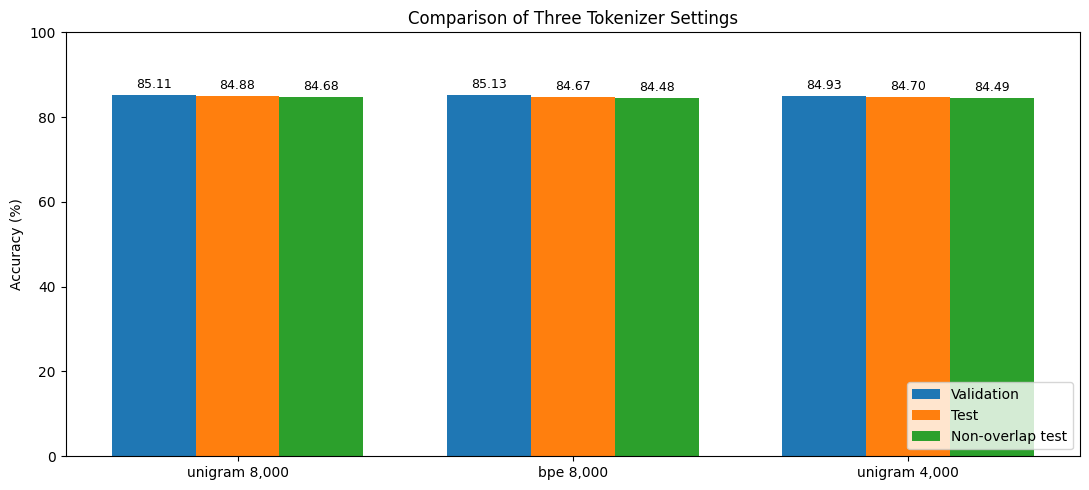

In [71]:
experiment_labels = [
    f"{result['tokenizer']} {result['vocab_size']:,}"
    for result in comparison_results
]

metrics = [
    ("val_accuracy", "Validation"),
    ("test_accuracy", "Test"),
    ("nonoverlap_test_accuracy", "Non-overlap test")
]

x = np.arange(len(comparison_results))
width = 0.25

fig, ax = plt.subplots(figsize=(11, 5))

for offset, (key, label) in zip([-width, 0, width], metrics):
    scores = [result[key] * 100 for result in comparison_results]
    bars = ax.bar(x + offset, scores, width, label=label)
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(experiment_labels)
ax.set_ylim(0, 100)
ax.set_ylabel("Accuracy (%)")
ax.set_title("Comparison of Three Tokenizer Settings")
ax.legend(loc="lower right")

plt.tight_layout()
plt.savefig(
    "results/all_experiments_accuracy.png",
    dpi=150, bbox_inches="tight"
)
plt.show()


# 세 설정 모두 학습이 진행되면서 train loss는 감소했지만, validation loss는 초기 최저점 이후 증가했다. 이번 실험에서는 토큰화 방식이나 사전 크기를 변경하는 것만으로 과적합이 해소되지 않았다. 선택된 모델의 테스트 정확도는 모두 84%대였으며, 설정 간 차이는 작았다.

# konlpy 형태소 분류기 실험




In [72]:
import importlib.util
import shutil

for module_name in ["konlpy", "MeCab", "mecab", "jpype"]:
    available = importlib.util.find_spec(module_name) is not None
    print(f"{module_name} 설치 여부:", available)

print("Java 실행 파일:", shutil.which("java"))

konlpy 설치 여부: True
MeCab 설치 여부: True
mecab 설치 여부: False
jpype 설치 여부: True
Java 실행 파일: /usr/bin/java


In [73]:
from konlpy.tag import Mecab

morph_analyzer = Mecab()

review = "이 영화 진짜 재밌어요ㅋㅋ"

print("원문:", review)
print("형태소:", morph_analyzer.morphs(review))
print("형태소와 품사:", morph_analyzer.pos(review))

print("\nSentencePiece unigram:")
print(sp_nsmc.encode(review, out_type=str))

원문: 이 영화 진짜 재밌어요ㅋㅋ
형태소: ['이', '영화', '진짜', '재밌', '어요', 'ㅋㅋ']
형태소와 품사: [('이', 'MM'), ('영화', 'NNG'), ('진짜', 'MAG'), ('재밌', 'VA'), ('어요', 'EF'), ('ㅋㅋ', 'IC')]

SentencePiece unigram:
['▁이', '▁영화', '▁진짜', '▁재밌어요', 'ᄏᄏ']


In [74]:
mecab_train_tokens = [
    morph_analyzer.morphs(review)
    for review in train_df["document"]
]

mecab_val_tokens = [
    morph_analyzer.morphs(review)
    for review in val_df["document"]
]

print("첫 학습용 리뷰:", train_df.iloc[0]["document"])
print("형태소:", mecab_train_tokens[0])


첫 학습용 리뷰: 뭔지 몰라도 추억의 영구형님영화ㅎㅎ
형태소: ['뭔지', '몰라도', '추억', '의', '영구', '형', '님', '영화', 'ㅎㅎ']


# 학습용 리뷰에서 자주 등자하는 형태소 에 id부여

In [75]:
from collections import Counter

mecab_counts = Counter(
    token
    for tokens in mecab_train_tokens
    for token in tokens
)

MECAB_VOCAB_SIZE = 8000

# SentencePiece와 동일하게 UNK=0, PAD=1 사용
mecab_word_index = {"<unk>": 0, "<pad>": 1}

for token, _ in mecab_counts.most_common():
    if token not in mecab_word_index:
        mecab_word_index[token] = len(mecab_word_index)

    if len(mecab_word_index) >= MECAB_VOCAB_SIZE:
        break

def encode_mecab(tokens):
    return [mecab_word_index.get(token, 0) for token in tokens]

mecab_train_sequences = [
    encode_mecab(tokens) for tokens in mecab_train_tokens
]
mecab_val_sequences = [
    encode_mecab(tokens) for tokens in mecab_val_tokens
]

print("학습용에서 등장한 형태소 종류:", len(mecab_counts))
print("실제로 사용할 사전 크기:", len(mecab_word_index))
print("첫 리뷰의 ID:", mecab_train_sequences[0])
print("토큰이 0개인 학습용 리뷰 수:",
      sum(len(seq) == 0 for seq in mecab_train_sequences))
print("토큰이 0개인 검증용 리뷰 수:",
      sum(len(seq) == 0 for seq in mecab_val_sequences))


학습용에서 등장한 형태소 종류: 48825
실제로 사용할 사전 크기: 8000
첫 리뷰의 ID: [934, 1317, 486, 10, 2901, 464, 175, 5, 216]
토큰이 0개인 학습용 리뷰 수: 0
토큰이 0개인 검증용 리뷰 수: 0


In [76]:
def token_statistics(sequences, unk_id=0):
    lengths = np.array([len(seq) for seq in sequences])

    total_tokens = sum(len(seq) for seq in sequences)
    unknown_tokens = sum(
        seq.count(unk_id) for seq in sequences
    )
    reviews_with_unk = sum(
        unk_id in seq for seq in sequences
    )

    return {
        "평균 토큰 수": lengths.mean(),
        "95% 지점": np.percentile(lengths, 95),
        "최대 토큰 수": lengths.max(),
        "UNK 토큰 비율 (%)":
            unknown_tokens / total_tokens * 100,
        "UNK 포함 리뷰 비율 (%)":
            reviews_with_unk / len(sequences) * 100
    }


token_stats_df = pd.DataFrame({
    "unigram 학습": token_statistics(train_sequences),
    "MeCab 학습": token_statistics(mecab_train_sequences),
    "unigram 검증": token_statistics(val_sequences),
    "MeCab 검증": token_statistics(mecab_val_sequences)
})

display(token_stats_df.round(3))

,unigram 학습,MeCab 학습,unigram 검증,MeCab 검증
평균 토큰 수,17.357,18.772,17.368,18.698
95% 지점,52.000,56.000,52.000,55.000
최대 토큰 수,132.000,116.000,133.000,96.000
UNK 토큰 비율 (%),0.094,4.501,0.110,4.771
UNK 포함 리뷰 비율 (%),1.453,44.920,1.722,46.454


# 사전 크기를 8,000개로 맞췄을 때, MeCab의 검증 UNK 토큰 비율은 4.77%로 unigram의 0.11%보다 높았다. 이는 MeCab의 분석 실패율이 아니라, 분석된 형태소가 우리가 구성한 제한된 사전에 없었던 비율이다. 다만 UNK 비율만으로 분류 성능을 확정할 수는 없으므로, 동일한 LSTM 조건에서 평가하겠다.


In [77]:
mecab_train_dataset = ReviewDataset(
    mecab_train_sequences, train_labels
)
mecab_val_dataset = ReviewDataset(
    mecab_val_sequences, val_labels
)

# 기존 배치 함수와 동일한 PAD ID인지 확인
assert mecab_word_index["<pad>"] == sp_nsmc.pad_id() == 1

mecab_train_loader = DataLoader(
    mecab_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch,
    generator=torch.Generator().manual_seed(SEED)
)

mecab_val_loader = DataLoader(
    mecab_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch
)

torch.manual_seed(SEED)

mecab_model = SentimentLSTM(
    vocab_size=len(mecab_word_index),
    pad_id=mecab_word_index["<pad>"]
).to(device)

optimizer = torch.optim.Adam(
    mecab_model.parameters(), lr=0.001
)

print("MeCab 모델 준비 완료")

MeCab 모델 준비 완료


# UNK가 많은 mecab에서도 성능이 잘나올까?


In [78]:
mecab_prefix = "nsmc_mecab_8000"
mecab_checkpoint_path = f"{mecab_prefix}_lstm_best.pt"

mecab_best_val_loss = float("inf")
mecab_best_epoch = None
mecab_history = []

for epoch in range(1, MAX_EPOCHS + 1):
    start = time.perf_counter()

    train_loss, train_acc = train_one_epoch(
        mecab_model, mecab_train_loader
    )
    val_loss, val_acc = evaluate(
        mecab_model, mecab_val_loader
    )

    elapsed = time.perf_counter() - start

    mecab_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_acc": train_acc,
        "val_acc": val_acc,
        "elapsed_seconds": elapsed
    })

    saved = ""
    if val_loss < mecab_best_val_loss:
        mecab_best_val_loss = val_loss
        mecab_best_epoch = epoch

        torch.save({
            "epoch": epoch,
            "model_state_dict": mecab_model.state_dict(),
            "val_loss": val_loss,
            "val_acc": val_acc
        }, mecab_checkpoint_path)

        saved = " | 검증 loss 최저 갱신 → 모델 저장"

    pd.DataFrame(mecab_history).to_csv(
        f"{mecab_prefix}_lstm_history.csv",
        index=False
    )

    print(
        f"Epoch {epoch:02d} | "
        f"train loss {train_loss:.4f}, acc {train_acc:.2%} | "
        f"val loss {val_loss:.4f}, acc {val_acc:.2%} | "
        f"{elapsed:.1f}초{saved}",
        flush=True
    )

print("\nMeCab 검증 loss 기준 선택 epoch:", mecab_best_epoch)

Epoch 01 | train loss 0.4105, acc 81.01% | val loss 0.3504, acc 84.41% | 24.4초 | 검증 loss 최저 갱신 → 모델 저장
Epoch 02 | train loss 0.3051, acc 86.89% | val loss 0.3254, acc 85.98% | 19.8초 | 검증 loss 최저 갱신 → 모델 저장
Epoch 03 | train loss 0.2558, acc 89.35% | val loss 0.3155, acc 86.50% | 19.8초 | 검증 loss 최저 갱신 → 모델 저장
Epoch 04 | train loss 0.2120, acc 91.45% | val loss 0.3236, acc 86.10% | 20.7초
Epoch 05 | train loss 0.1686, acc 93.43% | val loss 0.3626, acc 86.36% | 20.0초
Epoch 06 | train loss 0.1259, acc 95.29% | val loss 0.4161, acc 85.84% | 19.9초
Epoch 07 | train loss 0.0937, acc 96.62% | val loss 0.4715, acc 85.92% | 19.4초
Epoch 08 | train loss 0.0680, acc 97.60% | val loss 0.5833, acc 85.60% | 19.6초
Epoch 09 | train loss 0.0507, acc 98.23% | val loss 0.6328, acc 85.44% | 19.8초
Epoch 10 | train loss 0.0402, acc 98.60% | val loss 0.7050, acc 85.26% | 19.6초

MeCab 검증 loss 기준 선택 epoch: 3


In [79]:
# 검증 loss가 가장 낮았던 모델 복원
mecab_checkpoint = torch.load(
    mecab_checkpoint_path,
    map_location=device,
    weights_only=True
)
mecab_model.load_state_dict(
    mecab_checkpoint["model_state_dict"]
)

# 테스트에서는 사전을 새로 만들지 않습니다.
mecab_test_sequences = [
    encode_mecab(morph_analyzer.morphs(review))
    for review in test_clean["document"]
]

empty_count = sum(
    len(sequence) == 0 for sequence in mecab_test_sequences
)
print("토큰이 0개인 테스트 리뷰 수:", empty_count)

assert empty_count == 0, "빈 토큰열의 원문을 확인해야 합니다."

mecab_test_dataset = ReviewDataset(
    mecab_test_sequences,
    test_clean["label"].to_numpy()
)

mecab_test_loader = DataLoader(
    mecab_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch
)

mecab_unseen_loader = DataLoader(
    Subset(mecab_test_dataset, unseen_indices),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch
)

mecab_test_loss, mecab_test_acc = evaluate(
    mecab_model, mecab_test_loader
)
mecab_unseen_loss, mecab_unseen_acc = evaluate(
    mecab_model, mecab_unseen_loader
)

print("평가한 모델 epoch:", mecab_checkpoint["epoch"])
print(f"전체 유효 테스트 정확도: {mecab_test_acc:.2%}")
print(f"본문 비중복 테스트 정확도: {mecab_unseen_acc:.2%}")

토큰이 0개인 테스트 리뷰 수: 0
평가한 모델 epoch: 3
전체 유효 테스트 정확도: 86.13%
본문 비중복 테스트 정확도: 86.02%


In [80]:
mecab_result = {
    "tokenizer": "mecab",
    "vocab_size": len(mecab_word_index),
    "classifier": "LSTM",
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "selected_epoch": mecab_checkpoint["epoch"],
    "val_loss": mecab_checkpoint["val_loss"],
    "val_accuracy": mecab_checkpoint["val_acc"],
    "test_count": len(mecab_test_dataset),
    "test_loss": mecab_test_loss,
    "test_accuracy": mecab_test_acc,
    "nonoverlap_test_count": len(unseen_indices),
    "nonoverlap_test_loss": mecab_unseen_loss,
    "nonoverlap_test_accuracy": mecab_unseen_acc
}

comparison_results = [
    result for result in comparison_results
    if result["tokenizer"] != "mecab"
]
comparison_results.append(mecab_result)

comparison_df = pd.DataFrame(comparison_results)
comparison_df.to_csv(
    "results/tokenizer_comparison.csv",
    index=False
)

# CSV에는 0~1 수치로 보관하고, 화면에서는 %로 표시합니다.
display(
    comparison_df[[
        "tokenizer",
        "vocab_size",
        "selected_epoch",
        "val_accuracy",
        "test_accuracy",
        "nonoverlap_test_accuracy"
    ]].style.format({
        "val_accuracy": "{:.2%}",
        "test_accuracy": "{:.2%}",
        "nonoverlap_test_accuracy": "{:.2%}"
    })
)

,tokenizer,vocab_size,selected_epoch,val_accuracy,test_accuracy,nonoverlap_test_accuracy
0,unigram,8000,2,85.11%,84.88%,84.68%
1,bpe,8000,2,85.13%,84.67%,84.48%
2,unigram,4000,3,84.93%,84.70%,84.49%
3,mecab,8000,3,86.50%,86.13%,86.02%


# MeCab은 검증 데이터의 UNK 토큰 비율이 4.77%로 unigram의 0.11%보다 높았지만, 테스트 정확도는 86.13%로 unigram의 84.88%보다 높았다. 따라서 더 많은 토큰을 사전에 있는 ID로 표현할 수 있다는 사실만으로 분류 성능의 우위를 보장할 수는 없었다. 형태소 단위 분할이 이번 과제에 도움이 되었을 가능성은 있지만, 정규화와 입력 길이 등도 달라 원인을 하나로 확정할 수는 없다. 이 결과는 현재 데이터·모델·단일 시드 조건에 한정된다.

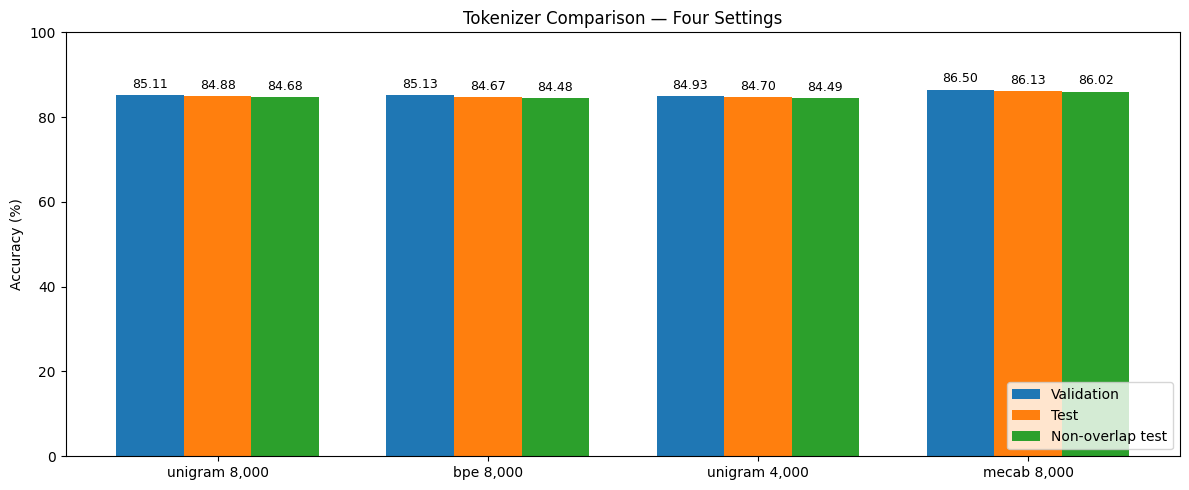

In [81]:
comparison_df = pd.DataFrame(comparison_results)

labels = [
    f"{row['tokenizer']} {row['vocab_size']:,}"
    for row in comparison_results
]

x = np.arange(len(labels))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 5))

metrics = [
    ("val_accuracy", "Validation"),
    ("test_accuracy", "Test"),
    ("nonoverlap_test_accuracy", "Non-overlap test")
]

for offset, (key, name) in zip([-width, 0, width], metrics):
    scores = [
        row[key] * 100 for row in comparison_results
    ]
    bars = ax.bar(x + offset, scores, width, label=name)
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 100)
ax.set_ylabel("Accuracy (%)")
ax.set_title("Tokenizer Comparison — Four Settings")
ax.legend(loc="lower right")

plt.tight_layout()
plt.savefig(
    "results/four_experiments_accuracy.png",
    dpi=150, bbox_inches="tight"
)
plt.show()

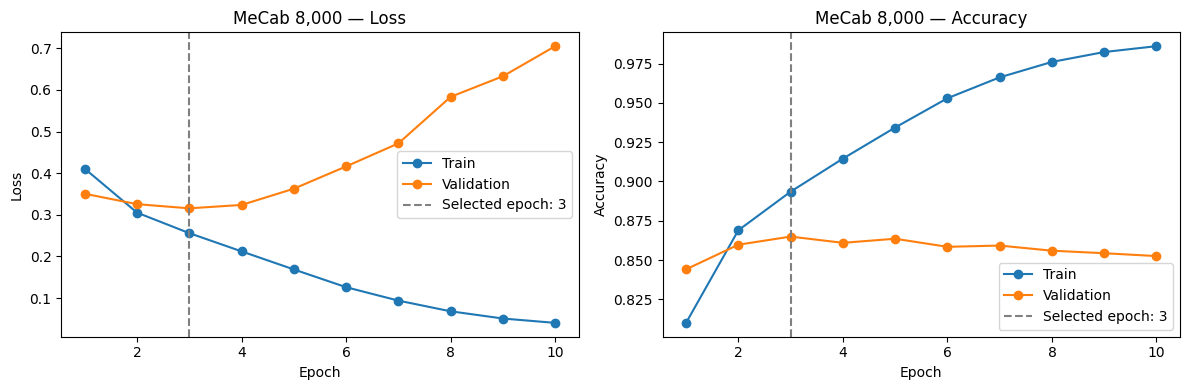

In [82]:
mecab_history_df = pd.DataFrame(mecab_history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, metric, ylabel in zip(
    axes, ["loss", "acc"], ["Loss", "Accuracy"]
):
    ax.plot(
        mecab_history_df["epoch"],
        mecab_history_df[f"train_{metric}"],
        marker="o", label="Train"
    )
    ax.plot(
        mecab_history_df["epoch"],
        mecab_history_df[f"val_{metric}"],
        marker="o", label="Validation"
    )
    ax.axvline(
        mecab_best_epoch,
        color="gray", linestyle="--",
        label=f"Selected epoch: {mecab_best_epoch}"
    )
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.set_title(f"MeCab 8,000 — {ylabel}")
    ax.legend()

plt.tight_layout()
plt.savefig(
    "results/mecab_8000_learning_curves.png",
    dpi=150, bbox_inches="tight"
)
plt.show()

MeCab 모델은 3 epoch에서 검증 loss가 가장 낮았다. 이후 학습 성능은 개선됐지만 검증 loss는 증가해 과적합 양상을 보였다. 따라서 3 epoch의 모델을 선택했다.

# 최종 결과와 루브릭 대응

| 설정 | 선택 epoch | 검증 정확도 | 테스트 정확도 | 본문 비중복 테스트 정확도 |
|---|---:|---:|---:|---:|
| unigram 8,000 | 2 | 85.11% | 84.88% | 84.68% |
| BPE 8,000 | 2 | 85.13% | 84.67% | 84.48% |
| unigram 4,000 | 3 | 84.93% | 84.70% | 84.49% |
| MeCab 8,000 | 3 | 86.50% | 86.13% | 86.02% |

1. 코퍼스 분석·전처리·SentencePiece 학습·토크나이저와 동적 패딩을 구현하고 출력으로 확인했다.
2. SentencePiece를 LSTM 분류기에 연결했고 unigram 8,000의 test accuracy는 84.88%로 80% 기준을 넘었다. 비중복 테스트에서도 84.68%였다.
3. model_type, vocab_size, MeCab을 동일한 데이터 분할과 LSTM 설정으로 비교했다. 각 모델은 검증 loss로 epoch를 선택했다.

MeCab은 UNK가 더 많았지만 이 조건에서 가장 높은 정확도를 보였다. unigram 4,000은 Embedding 파라미터가 512,000개 적었지만 평균 토큰 수가 늘어 속도 향상을 보장하지 않았다. 모든 모델은 후반에 과적합 양상을 보였다.

## 해석의 한계

- 단일 시드이며 반복 실험·통계적 유의성 검정을 하지 않았다.
- 학습·검증과 정확히 같은 본문이 있는 테스트 1,147행을 따로 제외한 점수도 보고했다. 비중복은 근접 중복·의미적 유사성까지 제거했다는 뜻이 아니다.
- 학습셋과 테스트셋의 행 정리 기준은 다르다. 학습은 결측·공백·라벨 충돌·중복을 정리했고 테스트는 본문 결측·공백만 제외했다.
- 실험마다 테스트를 중간에 열람했다. 모델 선택은 검증 loss를 사용했지만 완전히 봉인된 최종 holdout 실험이라고 주장하지 않는다.
- MeCab과 SentencePiece는 분할 외 정규화와 사전 구성도 달라 한 요인만으로 우위 원인을 확정할 수 없다.
- 같은 시드는 GPU의 완전 결정성을 보장하지 않으며, vocab_size를 바꾸면 파라미터 수와 난수 초기화 배치도 달라질 수 있다.

자세한 학습 과정은 저장소의 learning/ 및 analysis.md를 참고한다.
